# Chapitre 4 - Exercices 4.1 à 4.6

Ce notebook traite les six premiers exercices du chapitre 4, centrés sur les formats
d'encodage et l'évolution des schémas :

- **4.1** : compter les octets à la main dans chaque format (calcul) ;
- **4.2** : varints, zigzag et encodage différentiel d'horodatages (calcul et
  mini-lab) ;
- **4.3** : grands identifiants et Base64, les pièges des formats textuels (calcul) ;
- **4.4** : écrire un vérificateur d'évolution de schémas Protocol Buffers (mini-lab) ;
- **4.5** : décoder un enregistrement Avro à la main et prédire la résolution
  (raisonnement) ;
- **4.6** : registre de schémas, compatibilité transitive et rétention (raisonnement
  et code).

In [1]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
rng = np.random.default_rng(0)

## Exercice 4.1 : compter les octets à la main

**Énoncé.** On encode l'enregistrement
`{"userName": "Zoé", "favoriteNumber": -200, "interests": ["vélo"]}` (attention : `é` est
un caractère non ASCII).

1. Combien d'octets en JSON compact ? en MessagePack ?
2. Combien d'octets en Protocol Buffers avec le schéma du cours (`int64
   favorite_number = 2`) ? Et si le champ est déclaré `sint64` ?
3. Combien d'octets en Avro avec le schéma `Person` du cours ?
4. Classer les formats et expliquer l'écart entre `int64` et `sint64`.

5. Combien d'octets en Thrift BinaryProtocol et CompactProtocol ?

**Rappels.** UTF-8 code `é` sur 2 octets. MessagePack : chaîne courte = 1 octet
(`0xa0 | longueur`) + contenu ; entier de -32 768 à 32 767 hors des plages courtes : 1
octet de type + 2. Protobuf : clé d'un octet (numéro < 16), longueurs et entiers en
varint ; un `int64` négatif est écrit en complément à deux sur 64 bits, donc en 10 octets
de varint ; `sint64` utilise le zigzag. Avro : longueurs et entiers en zigzag, indice de
branche d'union, tableau = compte + éléments + 0 (cours 1 à 3, sections *Binary encoding*,
*Thrift and Protocol Buffers*, *Avro*).

**Solution.**

*1. JSON.* `{"userName":"Zoé","favoriteNumber":-200,"interests":["vélo"]}` compte 61
caractères, dont 2 `é` de 2 octets : **63 octets**. *MessagePack* : en-tête de map (1) ;
`userName` (1 + 8) ; `Zoé` (1 + 4) ; `favoriteNumber` (1 + 14) ; -200 ne tient pas dans
l'entier négatif court (-32 à -1) : `0xd1` + 2 octets (3) ; `interests` (1 + 9) ; tableau
d'un élément (1) ; `vélo` (1 + 5). Total : 1 + 9 + 5 + 15 + 3 + 10 + 1 + 6 = **50 octets**.

*2. Protobuf.* Champ 1 : clé + longueur + 4 octets = 6. Champ 2 en `int64` : -200 en
complément à deux a ses bits de poids fort à 1, le varint fait **10 octets**, plus la
clé : 11. Champ 3 : clé + longueur + 5 = 7. Total **24 octets**. En `sint64` : zigzag(-200)
= 399, qui tient sur 2 octets de varint (399 < 16 384) : 1 + 2 = 3, total **16 octets**.

*3. Avro.* Longueur 4 en zigzag (1 octet `08`) + 4 octets ; indice de branche 1 (1 octet) +
zigzag(-200) = 399 sur 2 octets ; tableau : compte (1) + longueur (1) + 5 octets + fin
(1). Total : 5 + 3 + 8 = **16 octets**.

*4.* Avro (16) = Protobuf `sint64` (16) < Protobuf `int64` (24) < MessagePack (50) < JSON
(63). Un `int64` négatif coûte toujours 10 octets en protobuf : pour un champ qui peut être
négatif, `sint64` est le bon choix.

*5. Thrift.* BinaryProtocol : chaque en-tête de champ fait 3 octets, les longueurs 4, un
`i64` 8 : (3 + 4 + 4) + (3 + 8) + (3 + 1 + 4 + 4 + 5) + 1 (fin) = **40 octets**.
CompactProtocol : (1 + 1 + 4) + (1 + 2) + (1 + 1 + 1 + 5) + 1 = **18 octets** (les entiers
sont toujours en zigzag).

**Vérification.**

In [2]:
zoe = {"userName": "Zoé", "favoriteNumber": -200, "interests": ["vélo"]}
PB_S = PbMessage("Person", [PbField("user_name", 1, "string"), PbField("favorite_number", 2, "sint64"),
                            PbField("interests", 3, "string", repeated=True)])
tailles = {"JSON compact": len(E.json_bytes(zoe)), "MessagePack": len(E.msgpack_encode(zoe)),
           "Protobuf (int64)": len(E.pb_encode(E.to_pb_record(zoe), E.PERSON_PB)),
           "Protobuf (sint64)": len(E.pb_encode(E.to_pb_record(zoe), PB_S)),
           "Avro": len(E.avro_encode(zoe, E.PERSON_AVRO))}
print(tailles)

{'JSON compact': 63, 'MessagePack': 50, 'Protobuf (int64)': 24, 'Protobuf (sint64)': 16, 'Avro': 16}


In [3]:
print({"Thrift BinaryProtocol": len(E.thrift_binary_encode(zoe)), "Thrift CompactProtocol": len(E.thrift_compact_encode(zoe))})

{'Thrift BinaryProtocol': 40, 'Thrift CompactProtocol': 18}


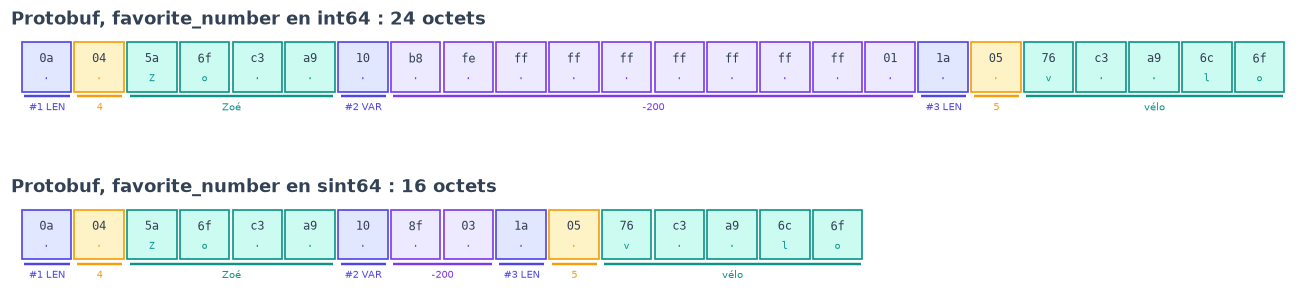

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 3.6))
for ax, (nom, sch) in zip(axes, [("int64", E.PERSON_PB), ("sint64", PB_S)]):
    tr = []
    b = E.pb_encode(E.to_pb_record(zoe), sch, tr)
    E.draw_byte_map(b, tr, title=f"Protobuf, favorite_number en {nom} : {len(b)} octets", per_row=24, ax=ax)
plt.tight_layout(); plt.show()

La carte d'octets montre les 10 octets `b8 fe ff ... ff 01` du `int64` négatif, réduits à
`8f 03` en `sint64`.

> **À retenir.** Compter les octets, c'est additionner en-têtes, longueurs et valeurs ;
> les noms de champs dominent les formats sans schéma, et le choix du type entier
> (complément à deux ou zigzag) peut multiplier par cinq la taille d'un nombre négatif.

## Exercice 4.2 : varints, zigzag et encodage différentiel

**Énoncé.** Un capteur envoie des horodatages en millisecondes (ordre de grandeur
$1{,}5 \cdot 10^{12}$), un toutes les 1 000 ms environ (gigue de ±50 ms).

1. Combien d'octets un varint utilise-t-il pour une valeur de $b$ bits ? Pour un
   horodatage ?
2. On transmet des lots de 1 000 horodatages dans un champ `repeated` compacté. Comparer
   trois encodages : `fixed64`, varint des valeurs brutes, varint (zigzag) des **écarts**
   successifs (le premier en valeur absolue).
3. Si l'écart moyen est $d$ millisecondes, à partir de quel $d$ l'encodage différentiel
   perd-il son avantage sur `fixed64` ?

**Rappels.** Un varint transporte 7 bits utiles par octet ; zigzag : $z = 2n$ si
$n \ge 0$, $-2n - 1$ sinon (cours 2, section 2). Un champ `repeated` compacté écrit une
clé, une longueur, puis les valeurs à la suite.

**Solution.**

*1.* $\max(1, \lceil b / 7 \rceil)$ octets. $1{,}5 \cdot 10^{12} < 2^{41}$ ($\approx 2{,}2
\cdot 10^{12}$) : 41 bits, donc $\lceil 41/7 \rceil = 6$ octets.

*2.* `fixed64` : 8 octets par valeur, soit environ 8 000 octets. Varint brut : 6 octets par
valeur, environ 6 000. Différentiel : un écart d'environ 1 000 vaut, en zigzag, environ
2 000, soit 11 bits, donc 2 octets ; plus 6 octets pour la première valeur : environ
2 000 octets, **quatre fois moins** que `fixed64`.

*3.* L'écart zigzagué vaut $2d$ ; il faut $\lceil \log_2(2d+1)/7 \rceil$ octets. Il reste
sous 8 octets tant que $2d < 2^{56}$, c'est-à-dire toujours en pratique ; mais il ne bat
plus le varint brut (6 octets) que si $2d < 2^{35}$, soit $d$ inférieur à environ 200 jours.
L'encodage différentiel est donc gagnant dès que les valeurs sont **triées et proches**.

{'fixed64': 8003, 'varint brut': 6003, 'varint des écarts (zigzag)': 2007}


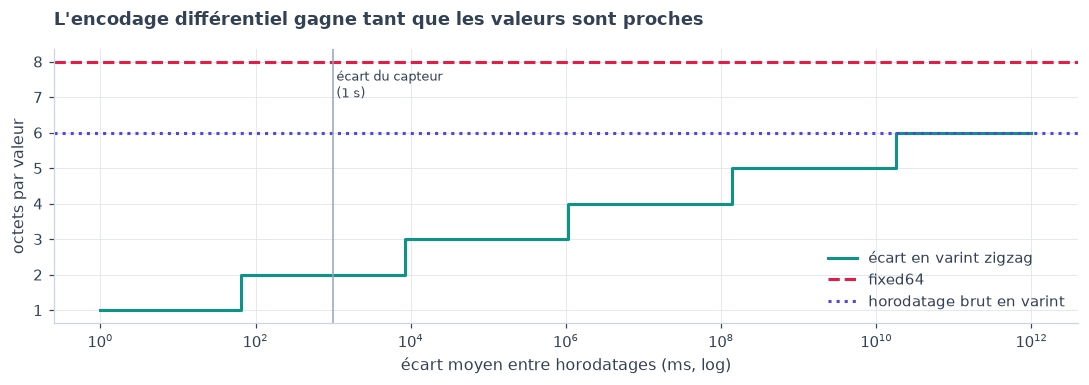

In [5]:
t0 = 1_546_300_800_000
ts = t0 + np.cumsum(rng.integers(950, 1051, 1000))
deltas = np.diff(np.concatenate([[0], ts]))
s_u64 = PbMessage("Lot", [PbField("t", 1, "uint64", repeated=True)])
s_f64 = PbMessage("Lot", [PbField("t", 1, "fixed64", repeated=True)])
s_s64 = PbMessage("Lot", [PbField("t", 1, "sint64", repeated=True)])
lots = {"fixed64": len(E.pb_encode({"t": [int(x) for x in ts]}, s_f64)),
        "varint brut": len(E.pb_encode({"t": [int(x) for x in ts]}, s_u64)),
        "varint des écarts (zigzag)": len(E.pb_encode({"t": [int(x) for x in deltas]}, s_s64))}
assert np.array_equal(np.cumsum(E.pb_decode(E.pb_encode({"t": [int(x) for x in deltas]}, s_s64), s_s64)["t"]), ts)
print(lots)

d = np.logspace(0, 12, 200)
taille = [E.uvarint_size(E.zigzag_encode(int(x))) for x in d]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(d, taille, where="post", color=TEAL, label="écart en varint zigzag")
ax.axhline(8, color=ROSE, ls="--", label="fixed64")
ax.axhline(6, color=INDIGO, ls=":", label="horodatage brut en varint")
ax.axvline(1000, color=GRAY, lw=1); ax.text(1100, 7.0, "écart du capteur\n(1 s)", fontsize=8.5, color=SLATE)
ax.set_xscale("log"); ax.set_xlabel("écart moyen entre horodatages (ms, log)"); ax.set_ylabel("octets par valeur")
ax.set_title("L'encodage différentiel gagne tant que les valeurs sont proches")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Mesuré : 8 003, 6 003 et 2 007 octets (les 3 octets d'en-tête du champ compacté et les 6
octets de la première valeur compris). C'est la même idée que la compression des colonnes
triées (chapitre 3).

> **À retenir.** Un varint coûte $\lceil b/7 \rceil$ octets ; sur des valeurs triées,
> encoder les écarts (en zigzag) plutôt que les valeurs divise la taille par trois ou
> quatre.

## Exercice 4.3 : grands identifiants et Base64

**Énoncé.** Un service attribue des identifiants de 64 bits à la manière de Snowflake :
`id = (t << 22) | (machine << 12) | séquence`, où $t$ est le nombre de millisecondes
écoulées depuis une époque propre au service.

1. Au bout de combien de temps après l'époque les identifiants dépassent-ils $2^{53}$ ?
2. Un client JavaScript lit les identifiants comme des nombres JSON (doubles). Pour un
   identifiant tiré uniformément dans $[2^{62}, 2^{63}[$, quelle est la probabilité qu'il
   soit relu exactement ? Quelle erreur maximale ?
3. Une API renvoie des vignettes d'images de 30 Kio en Base64 dans du JSON. Quel est le
   surcoût en octets pour 1 million de vignettes par jour ?

**Rappels.** Un double représente exactement tous les entiers jusqu'à $2^{53}$ ; entre
$2^{k}$ et $2^{k+1}$, l'écart entre doubles consécutifs vaut $2^{k-52}$. Base64 : 4
caractères pour 3 octets, avec remplissage (cours 1, section 4).

**Solution.**

*1.* $t \cdot 2^{22} > 2^{53} \iff t > 2^{31}$ ms $\approx 2{,}15 \cdot 10^9$ ms, soit
**24,9 jours**. Quelques semaines après la mise en service, plus aucun identifiant n'est
représentable exactement.

*2.* Dans $[2^{62}, 2^{63}[$, l'écart entre doubles vaut $2^{62-52} = 1\,024$ : seul un
identifiant multiple de 1 024 survit, probabilité **1/1 024** (environ 0,1 %). L'arrondi au
plus proche fait une erreur d'au plus **512**. C'est pourquoi les API concernées renvoient
aussi l'identifiant sous forme de chaîne.

*3.* $30 \times 1\,024 = 30\,720$ octets donnent $4 \lceil 30\,720 / 3 \rceil = 40\,960$
caractères : 10 240 octets de plus par vignette, soit **10,24 Go par jour** (un tiers de
plus), avant compression HTTP éventuelle.

In [6]:
print(f"1. dépassement de 2^53 après {2 ** 31 / 1000 / 86400:.1f} jours")
ids = rng.integers(2 ** 62, 2 ** 63 - 1, 200_000, dtype=np.int64)
relus = np.array([int(float(int(x))) for x in ids], dtype=object)
exacts = np.mean([int(a) == b for a, b in zip(ids, relus)])
erreur = max(abs(int(a) - b) for a, b in zip(ids[:20000], relus[:20000]))
print(f"2. relus exactement : {exacts:.4%} (théorie {1 / 1024:.4%}) ; erreur maximale observée : {erreur}")
import base64
print(f"3. surcoût par vignette : {len(base64.b64encode(bytes(30 * 1024))) - 30 * 1024} octets ; "
      f"par jour : {(len(base64.b64encode(bytes(30 * 1024))) - 30 * 1024) * 1e6 / 1e9:.2f} Go")

1. dépassement de 2^53 après 24.9 jours
2. relus exactement : 0.0895% (théorie 0.0977%) ; erreur maximale observée : 512
3. surcoût par vignette : 10240 octets ; par jour : 10.24 Go


> **À retenir.** Des identifiants de 64 bits dépassent $2^{53}$ presque immédiatement ;
> un client qui les lit en double les corrompt (erreur jusqu'à 512 vers $2^{62}$). Base64
> ajoute un tiers au volume des données binaires.